# Why are Japan's regions losing people?

Data: Social and Demographic Statistics System (SSDS), Statistics Bureau of Japan, via the e-Stat API.
47 prefectures, 1975–2024.

1. Get and prepare the data
2. Feature selection: which statistics matter most?
3. ANOVA: does population change differ between regions and between periods?
4. Prediction: population 5 and 10 years ahead

## 1. Get and prepare the data

In [1]:
# Setup: libraries and the e-Stat key
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from urllib.parse import quote
# The key: from the Colab secret on Colab, or from the .env file on your own computer
try:
    from google.colab import userdata
    APP_ID = userdata.get("ESTAT_APP_ID")
except ImportError:
    for line in open(".env"):
        if line.startswith("ESTAT_APP_ID="):
            APP_ID = line.split("=", 1)[1].strip()

In [2]:
# Function: download one statistic from e-Stat as a table (area, year, value)
def get_estat(table_id, item_code):
    url = ("https://api.e-stat.go.jp/rest/3.0/app/getSimpleStatsData"
           f"?appId={APP_ID}&lang=E&statsDataId={table_id}&cdCat01={quote(item_code)}"
           "&metaGetFlg=Y&cntGetFlg=N&explanationGetFlg=N&annotationGetFlg=N"
           "&sectionHeaderFlg=2&replaceSpChars=0")
    df = pd.read_csv(url, dtype={"area_code": str})
    df["value"] = pd.to_numeric(df["value"], errors="coerce")
    df = df.rename(columns={"AREA": "area", "SURVEY YEAR": "year"})
    return df[["area_code", "area", "year", "value"]]

# test
get_estat("0000010101", "A1101").head()

,area_code,area,year,value
0,00000,All Japan,1975,111939643
1,00000,All Japan,1976,113094000
2,00000,All Japan,1977,114165000
3,00000,All Japan,1978,115190000
4,00000,All Japan,1979,116155000


In [3]:
# The statistics we want: one or two per topic (table_id + item_code from e-Stat)
tables = {
    # Population
    "pop":               {"table_id": "0000010101", "item_code": "A1101"},     # total population
    "births":            {"table_id": "0000010101", "item_code": "A4101"},     # births
    "deaths":            {"table_id": "0000010101", "item_code": "A4200"},     # deaths
    "moves_in":          {"table_id": "0000010101", "item_code": "A5101"},     # people moving in
    "moves_out":         {"table_id": "0000010101", "item_code": "A5102"},     # people moving out
    "pop_65plus":        {"table_id": "0000010101", "item_code": "A1303"},     # people aged 65+
    # Family
    "fertility":         {"table_id": "0000010201", "item_code": "#A05203"},   # babies per woman
    "marriage_rate":     {"table_id": "0000010201", "item_code": "#A06601"},   # marriages per 1,000 people
    "single_households": {"table_id": "0000010201", "item_code": "#A06205"},   # people living alone (%)
    # Land and weather
    "density":           {"table_id": "0000010201", "item_code": "#A01202"},   # people per km2 of habitable land
    "snow_days":         {"table_id": "0000010202", "item_code": "#B02304"},   # days of snow per year
    "temperature":       {"table_id": "0000010202", "item_code": "#B02101"},   # average temperature
    # Income and money
    "income_per_taxpayer": {"table_id": "0000010204", "item_code": "#D02206"}, # taxable income per taxpayer
    "household_income":  {"table_id": "0000010212", "item_code": "#L01201"},   # monthly income of worker households
    "savings_rate":      {"table_id": "0000010212", "item_code": "#L02734"},   # household savings rate (%)
    # Jobs
    "unemployment":      {"table_id": "0000010206", "item_code": "#F01301"},   # unemployment rate (%)
    "job_openings":      {"table_id": "0000010206", "item_code": "#F03103"},   # job openings per job seeker
    # Public finance
    "fiscal_strength":   {"table_id": "0000010204", "item_code": "#D0110101"}, # prefecture's own tax strength
    # Education
    "univ_rate":         {"table_id": "0000010205", "item_code": "#E09402"},   # high-school grads going to university (%)
    "univ_capacity":     {"table_id": "0000010205", "item_code": "#E0610202"}, # university places vs local students
    # Culture
    "libraries":         {"table_id": "0000010207", "item_code": "#G01104"},   # libraries per 1 million people
    # Housing
    "homeownership":     {"table_id": "0000010208", "item_code": "#H01301"},   # homes owned (%)
    "vacancy_rate":      {"table_id": "0000010208", "item_code": "#H01405"},   # empty homes (%)
    "rent":              {"table_id": "0000010208", "item_code": "#H04102"},   # private rent (yen per 3.3 m2)
    # Health
    "doctors":           {"table_id": "0000010209", "item_code": "#I0920101"}, # doctors per 100,000 people
    "hospitals":         {"table_id": "0000010209", "item_code": "#I0910103"}, # hospitals per 100,000 people
    # Welfare and childcare
    "childcare_use":     {"table_id": "0000010205", "item_code": "#E0910402"}, # children using nurseries (%)
    "elderly_homes":     {"table_id": "0000010210", "item_code": "#J022011"},  # elderly homes per 100,000 people 65+
    "welfare":           {"table_id": "0000010210", "item_code": "#J01107"},   # people on welfare per 1,000
    # Safety
    "crime":             {"table_id": "0000010211", "item_code": "#K06101"},   # crimes per 1,000 people
    "traffic_accidents": {"table_id": "0000010211", "item_code": "#K04101"},   # traffic accidents per 100,000 people
}

In [4]:
# Download every statistic in the dictionary (about 1 minute)
dfs = {}

for name, info in tables.items():
    dfs[name] = get_estat(info["table_id"], info["item_code"])
    print(name, "downloaded:", len(dfs[name]), "rows")

pop downloaded: 2400 rows
births downloaded: 2112 rows
deaths downloaded: 2352 rows
moves_in downloaded: 2448 rows
moves_out downloaded: 2448 rows
pop_65plus downloaded: 2400 rows
fertility downloaded: 1920 rows
marriage_rate downloaded: 2304 rows
single_households downloaded: 432 rows
density downloaded: 2400 rows
snow_days downloaded: 2208 rows
temperature downloaded: 2400 rows
income_per_taxpayer downloaded: 1920 rows
household_income downloaded: 2400 rows
savings_rate downloaded: 2400 rows
unemployment downloaded: 480 rows
job_openings downloaded: 2304 rows
fiscal_strength downloaded: 2304 rows
univ_rate downloaded: 1152 rows
univ_capacity downloaded: 2352 rows
libraries downloaded: 1488 rows
homeownership downloaded: 480 rows
vacancy_rate downloaded: 480 rows
rent downloaded: 2400 rows
doctors downloaded: 1344 rows
hospitals downloaded: 2352 rows
childcare_use downloaded: 2208 rows
elderly_homes downloaded: 1296 rows
welfare downloaded: 2352 rows
crime downloaded: 2352 rows
traffi

In [5]:
# Combine into one table: one row per area and year, one column per statistic
combined = None

for name, df in dfs.items():
    df = df.rename(columns={"value": name})
    if combined is None:
        combined = df
    else:
        combined = combined.merge(df, on=["area_code", "area", "year"], how="outer")

print(combined.shape)
combined.head()

(2448, 34)


,area_code,area,year,pop,births,deaths,moves_in,moves_out,pop_65plus,fertility,...,homeownership,vacancy_rate,rent,doctors,hospitals,childcare_use,elderly_homes,welfare,crime,traffic_accidents
0,00000,All Japan,1975,111939643.0,NaN,702275.0,3697721,3697721,8865429.0,NaN,...,NaN,NaN,NaN,112.5,6.5,96.0,NaN,12.05,11.03,422.5
1,00000,All Japan,1976,113094000.0,NaN,703270.0,3565121,3565121,9201000.0,NaN,...,NaN,NaN,NaN,113.6,6.5,96.4,NaN,12.01,11.03,416.5
2,00000,All Japan,1977,114165000.0,NaN,690074.0,3567559,3567559,9561000.0,NaN,...,NaN,NaN,NaN,115.3,6.5,96.7,NaN,12.20,11.11,403.5
3,00000,All Japan,1978,115190000.0,NaN,695821.0,3487439,3487439,9921000.0,NaN,...,60.4,7.6,NaN,118.2,6.5,96.1,NaN,12.40,11.61,402.8
4,00000,All Japan,1979,116155000.0,NaN,689664.0,3469432,3469432,10309000.0,NaN,...,NaN,NaN,NaN,123.2,6.7,95.2,NaN,12.32,11.10,406.0


In [6]:
# How many values are missing per column (NaN = not collected that year, e.g. census only every 5 years)
combined.isna().sum()

area_code                 0
area                      0
year                      0
pop                      48
births                  336
deaths                   96
moves_in                  0
moves_out                 0
pop_65plus               48
fertility               528
marriage_rate           144
single_households      2016
density                  48
snow_days               323
temperature              99
income_per_taxpayer     528
household_income         48
savings_rate             48
unemployment           1968
job_openings            144
fiscal_strength         144
univ_rate              1296
univ_capacity            96
libraries              1132
homeownership          1968
vacancy_rate           1968
rent                     98
doctors                1104
hospitals                96
childcare_use           240
elderly_homes          1152
welfare                  96
crime                    96
traffic_accidents        48
dtype: int64

In [7]:
# Separate the whole of Japan from the 47 prefectures, and turn counts into rates
japan = combined[combined["area"] == "All Japan"].copy()
pref  = combined[combined["area"] != "All Japan"].copy()

for df in [japan, pref]:
    df["aging_rate"]    = df["pop_65plus"] / df["pop"] * 100                     # % aged 65+
    df["natural_rate"]  = (df["births"] - df["deaths"]) / df["pop"] * 1000       # births - deaths per 1,000
    df["net_migration"] = (df["moves_in"] - df["moves_out"]) / df["pop"] * 1000  # moves in - out per 1,000

pref = pref.sort_values(["area_code", "year"])
pref.head()

,area_code,area,year,pop,births,deaths,moves_in,moves_out,pop_65plus,fertility,...,doctors,hospitals,childcare_use,elderly_homes,welfare,crime,traffic_accidents,aging_rate,natural_rate,net_migration
51,01000,Hokkaido,1975,5338206.0,NaN,31037.0,84738,89913,366651.0,NaN,...,99.9,8.1,97.2,NaN,18.70,14.71,299.2,6.868431,NaN,-0.969427
52,01000,Hokkaido,1976,5395000.0,NaN,30177.0,82355,83250,386000.0,NaN,...,102.8,8.1,97.1,NaN,18.76,14.68,306.8,7.154773,NaN,-0.165894
53,01000,Hokkaido,1977,5443000.0,NaN,30428.0,81543,85872,406000.0,NaN,...,103.9,8.0,97.0,NaN,19.55,14.05,302.5,7.459122,NaN,-0.795333
54,01000,Hokkaido,1978,5490000.0,NaN,30932.0,79548,83902,425000.0,NaN,...,106.2,8.2,96.6,NaN,19.93,14.97,297.5,7.741348,NaN,-0.793078
55,01000,Hokkaido,1979,5535000.0,NaN,31091.0,80885,82709,446000.0,NaN,...,110.8,8.5,95.8,NaN,19.96,14.43,302.6,8.057814,NaN,-0.329539


In [8]:
# Group prefectures into 8 regions (area_code: 01 = Hokkaido ... 47 = Okinawa, north to south)
def region(code):
    n = int(code[:2])
    if n == 1:   return "Hokkaido"
    if n <= 7:   return "Tohoku"
    if n <= 14:  return "Kanto"
    if n <= 23:  return "Chubu"
    if n <= 30:  return "Kinki"
    if n <= 35:  return "Chugoku"
    if n <= 39:  return "Shikoku"
    return "Kyushu-Okinawa"

pref["region"] = pref["area_code"].apply(region)
pref.groupby("region")["area"].nunique()   # prefectures per region

region
Chubu             9
Chugoku           5
Hokkaido          1
Kanto             7
Kinki             7
Kyushu-Okinawa    8
Shikoku           4
Tohoku            6
Name: area, dtype: int64

In [9]:
# Mark Fukushima after 2011 (nuclear evacuation, not normal population decline)
pref["fukushima_after_2011"] = (pref["area"] == "Fukushima-ken") & (pref["year"] >= 2011)
pref["fukushima_after_2011"].sum()

np.int64(15)

In [10]:
# Remove years with no population data (2025 has only migration numbers)
pref = pref.dropna(subset=["pop"])
pref["year"].max()

np.int64(2024)

In [11]:
# Some surveys are not held in census years (e.g. housing: 1978, 1983, ...).
# Fill each gap with the latest earlier value, at most 4 years old.
features = ["aging_rate", "fertility", "income_per_taxpayer", "unemployment",
            "job_openings", "density", "univ_capacity", "doctors", "vacancy_rate", "snow_days",
            "marriage_rate", "household_income", "fiscal_strength", "rent", "hospitals",
            "childcare_use", "welfare", "crime"]

pref[features] = pref.groupby("area")[features].ffill(limit=4)

In [12]:
# 5-year table: keep census years and add the population change over the next 5 and 10 years
pref5 = pref[pref["year"] % 5 == 0].copy()

pref5["pop_next5"]   = pref5.groupby("area")["pop"].shift(-1)        # population 5 years later
pref5["pop_next10"]  = pref5.groupby("area")["pop"].shift(-2)        # population 10 years later
pref5["growth_5y"]   = (pref5["pop_next5"]  - pref5["pop"]) / pref5["pop"] * 100    # % change, next 5 years
pref5["growth_10y"]  = (pref5["pop_next10"] - pref5["pop"]) / pref5["pop"] * 100    # % change, next 10 years
pref5["growth_prev"] = pref5.groupby("area")["growth_5y"].shift(1)   # % change in the previous 5 years

pref5[pref5["area"] == "Akita-ken"][["area", "year", "pop", "growth_5y", "growth_10y", "growth_prev"]]

,area,year,pop,growth_5y,growth_10y,growth_prev
255,Akita-ken,1975,1232481.0,1.968712,1.748587,NaN
260,Akita-ken,1980,1256745.0,-0.215875,-2.328794,1.968712
265,Akita-ken,1985,1254032.0,-2.117490,-3.218817,-0.215875
270,Akita-ken,1990,1227478.0,-1.125153,-3.111991,-2.117490
275,Akita-ken,1995,1213667.0,-2.009447,-5.616532,-1.125153
280,Akita-ken,2000,1189279.0,-3.681054,-8.684421,-2.009447
285,Akita-ken,2005,1145501.0,-5.194583,-10.683710,-3.681054
290,Akita-ken,2010,1085997.0,-5.789887,-11.647822,-5.194583
295,Akita-ken,2015,1023119.0,-6.217947,NaN,-5.789887
300,Akita-ken,2020,959502.0,NaN,NaN,-6.217947


In [13]:
# Save the prepared tables
pref.to_csv("prefectures_yearly.csv", index=False)
pref5.to_csv("prefectures_5yr.csv", index=False)
japan.to_csv("japan.csv", index=False)

## 2. Feature selection: which statistics matter most?

Three methods each pick their **top 5** statistics. To compare the methods fairly, we train the same simple
model (linear regression) on each method's 5 statistics, **learn from the past (1985–2005) and test on the
most recent periods (2010–2020)**. The method whose statistics predict best wins.

In [14]:
# Data for feature selection: statistics at the start of each 5-year period -> change over the next 5 years
data = pref5[(pref5["fukushima_after_2011"] == False)].dropna(subset=features + ["growth_5y"])

train = data[data["year"] <= 2005]     # periods starting 1985 ... 2005 (learn)
test  = data[data["year"] >= 2010]     # periods starting 2010, 2015       (test)

print("train:", len(train), "rows, years", sorted(train["year"].unique()))
print("test: ", len(test),  "rows, years", sorted(test["year"].unique()))

train: 235 rows, years [np.int64(1985), np.int64(1990), np.int64(1995), np.int64(2000), np.int64(2005)]
test:  93 rows, years [np.int64(2010), np.int64(2015)]


Top 5 by correlation: ['aging_rate', 'marriage_rate', 'fiscal_strength', 'doctors', 'univ_capacity']


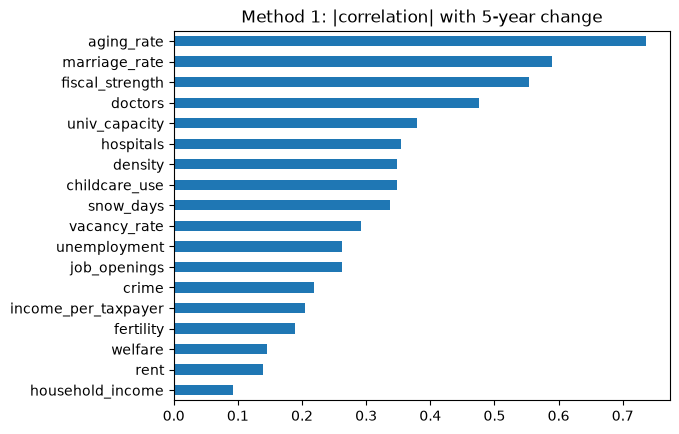

In [15]:
# Method 1: correlation - how strongly each statistic moves with population change (training data only)
corr = train[features + ["growth_5y"]].corr()["growth_5y"].drop("growth_5y")
corr_rank = corr.abs().sort_values(ascending=False)

top_corr = list(corr_rank.index[:5])
print("Top 5 by correlation:", top_corr)

corr_rank.sort_values().plot(kind="barh", title="Method 1: |correlation| with 5-year change")
plt.show()

Top 5 by random forest: ['aging_rate', 'fiscal_strength', 'marriage_rate', 'doctors', 'hospitals']


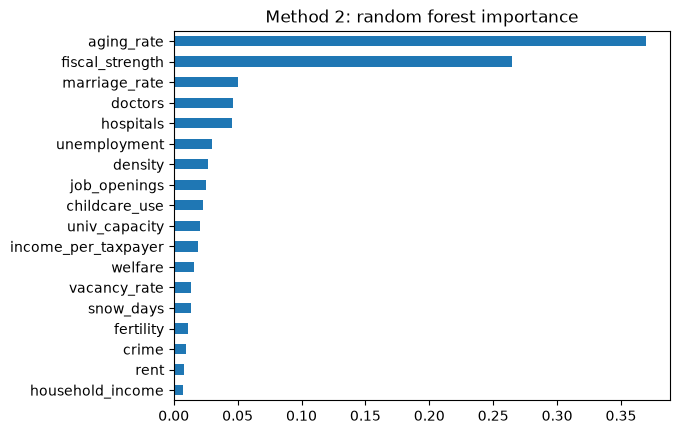

In [16]:
# Method 2: random forest - how much the model relies on each statistic to predict the change
from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor(n_estimators=500, random_state=0)
rf.fit(train[features], train["growth_5y"])
rf_rank = pd.Series(rf.feature_importances_, index=features).sort_values(ascending=False)

top_rf = list(rf_rank.index[:5])
print("Top 5 by random forest:", top_rf)

rf_rank.sort_values().plot(kind="barh", title="Method 2: random forest importance")
plt.show()

Top 5 by Lasso: ['aging_rate', 'snow_days', 'marriage_rate', 'hospitals', 'income_per_taxpayer']
Statistics Lasso dropped (coefficient = 0): ['fertility', 'density', 'vacancy_rate', 'univ_capacity', 'unemployment', 'household_income', 'rent', 'fiscal_strength', 'childcare_use', 'crime']


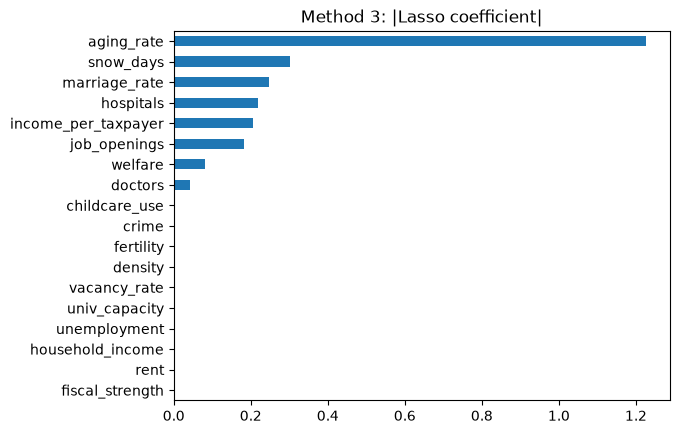

In [17]:
# Method 3: Lasso - a regression that shrinks unimportant statistics to zero
# (statistics are first put on the same scale, so their coefficients can be compared)
from sklearn.linear_model import LassoCV
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(train[features])

lasso = LassoCV(cv=5, random_state=0).fit(X_scaled, train["growth_5y"])
lasso_rank = pd.Series(abs(lasso.coef_), index=features).sort_values(ascending=False)

top_lasso = list(lasso_rank.index[:5])
print("Top 5 by Lasso:", top_lasso)
print("Statistics Lasso dropped (coefficient = 0):", list(lasso_rank[lasso_rank == 0].index))

lasso_rank.sort_values().plot(kind="barh", title="Method 3: |Lasso coefficient|")
plt.show()

                   MAE (percentage points)     R2
method                                           
Correlation                          1.017  0.579
Random forest                        1.002  0.611
Lasso                                1.078  0.563
All 18 statistics                    1.508  0.218


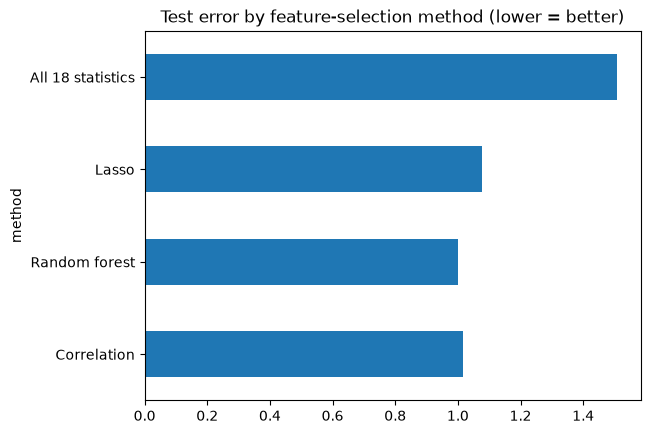

In [18]:
# Compare the methods: train the same linear regression on each method's top 5, test on 2010-2020
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score

candidates = {"Correlation": top_corr, "Random forest": top_rf, "Lasso": top_lasso, "All 18 statistics": features}
results = []

for method, cols in candidates.items():
    model = LinearRegression().fit(train[cols], train["growth_5y"])
    pred = model.predict(test[cols])
    results.append({"method": method,
                    "MAE (percentage points)": mean_absolute_error(test["growth_5y"], pred),
                    "R2": r2_score(test["growth_5y"], pred)})

results = pd.DataFrame(results).set_index("method").round(3)
print(results)

results["MAE (percentage points)"].plot(kind="barh", title="Test error by feature-selection method (lower = better)")
plt.show()

In [19]:
# Choose the best method (smallest error), not counting "all 18" which is only a reference
best_method = results.drop("All 18 statistics")["MAE (percentage points)"].idxmin()
selected = candidates[best_method]

print("Best method:", best_method)
print("Selected statistics:", selected)

# Which statistics each method picked (1 = picked)
picked = pd.DataFrame({m: [1 if f in cols else 0 for f in features] for m, cols in candidates.items() if m != "All 18 statistics"},
                      index=features)
picked[picked.sum(axis=1) > 0].sort_values(list(picked.columns), ascending=False)

Best method: Random forest
Selected statistics: ['aging_rate', 'fiscal_strength', 'marriage_rate', 'doctors', 'hospitals']


,Correlation,Random forest,Lasso
aging_rate,1,1,1
marriage_rate,1,1,1
doctors,1,1,0
fiscal_strength,1,1,0
univ_capacity,1,0,0
hospitals,0,1,1
income_per_taxpayer,0,0,1
snow_days,0,0,1


## 2b. Do the leading factors change over time?

The same correlation as Method 1, but calculated **separately for each period**:
about 30, 20 and 10 years ago, and now.

In [20]:
# Changing factors: correlation with the next 5 years' change, calculated separately for each period
periods = {"1985-1990 (~30 years ago)": 1985, "1995-2000 (~20 years ago)": 1995,
           "2005-2010 (~10 years ago)": 2005, "2015-2020 (now)": 2015}

by_period = {}
for label, year in periods.items():
    d = pref5[(pref5["year"] == year) & (pref5["fukushima_after_2011"] == False)].dropna(subset=["growth_5y"])
    by_period[label] = d[features + ["growth_5y"]].corr()["growth_5y"].drop("growth_5y")

by_period = pd.DataFrame(by_period).round(2)
by_period.sort_values("2015-2020 (now)")

,1985-1990 (~30 years ago),1995-2000 (~20 years ago),2005-2010 (~10 years ago),2015-2020 (now)
aging_rate,-0.72,-0.80,-0.89,-0.92
hospitals,-0.48,-0.49,-0.43,-0.47
snow_days,-0.33,-0.28,-0.48,-0.45
vacancy_rate,0.11,0.09,-0.19,-0.44
fertility,-0.04,-0.29,-0.36,-0.11
doctors,-0.48,-0.36,-0.16,-0.06
unemployment,-0.25,0.35,0.02,0.07
household_income,0.34,-0.00,0.03,0.10
welfare,-0.36,-0.14,0.02,0.14
job_openings,0.33,-0.35,0.48,0.16


In [21]:
# Top 3 factors in each period (largest correlation, positive or negative)
for label in by_period.columns:
    top3 = by_period[label].abs().sort_values(ascending=False).index[:3]
    print(label, "->", ", ".join(f"{f} ({by_period.loc[f, label]:+.2f})" for f in top3))

1985-1990 (~30 years ago) -> aging_rate (-0.72), income_per_taxpayer (+0.64), fiscal_strength (+0.53)
1995-2000 (~20 years ago) -> aging_rate (-0.80), marriage_rate (+0.76), income_per_taxpayer (+0.67)
2005-2010 (~10 years ago) -> marriage_rate (+0.92), aging_rate (-0.89), fiscal_strength (+0.81)
2015-2020 (now) -> aging_rate (-0.92), marriage_rate (+0.89), fiscal_strength (+0.79)


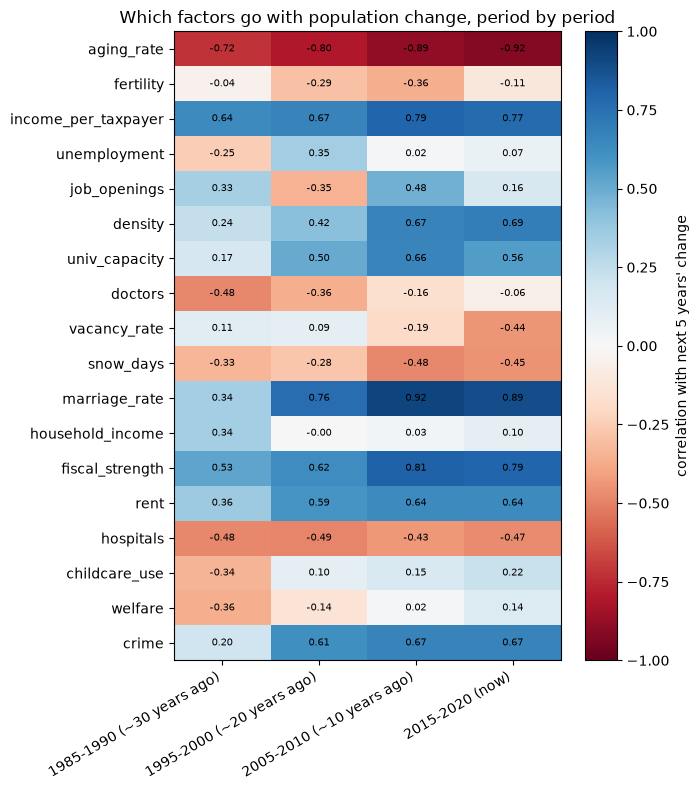

In [22]:
# Heatmap: blue = more of it goes with growth, red = more of it goes with decline
plt.figure(figsize=(7, 8))
plt.imshow(by_period.values, cmap="RdBu", vmin=-1, vmax=1, aspect="auto")
plt.colorbar(label="correlation with next 5 years' change")
plt.yticks(range(len(by_period)), by_period.index)
plt.xticks(range(len(by_period.columns)), by_period.columns, rotation=30, ha="right")
for i in range(by_period.shape[0]):
    for j in range(by_period.shape[1]):
        v = by_period.values[i, j]
        if not np.isnan(v):
            plt.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7)
plt.title("Which factors go with population change, period by period")
plt.tight_layout()
plt.show()

## 2c. Is the link real, or just a coincidence?

A correlation only shows that two things **move together**, not that one causes the other.
For example, richer prefectures have lower fertility, but is it the income, or is it that rich prefectures are big, expensive cities?

Two checks make a claim stronger:
- **Hold other factors fixed:** put all factors into one regression, comparing prefectures within the same period.
  If a factor's effect disappears, it was only standing in for something else.
- **Compare each prefecture with itself over time:** when the *same* prefecture's unemployment rises, does its fertility fall?
  This removes everything that is fixed about a place (culture, climate, city size).

A factor counts as a **real link** if it stays (p < 0.05). Even then it is an association, not proof of cause.

In [ ]:
# Data for the check: start of each 5-year period from 1985 (income data starts then), without Fukushima after 2011
import statsmodels.formula.api as smf

check_factors = ["income_per_taxpayer", "unemployment", "traffic_accidents", "aging_rate", "marriage_rate"]
check = pref5[(pref5["fukushima_after_2011"] == False) & (pref5["year"] >= 1985)]
check = check.dropna(subset=check_factors + ["fertility", "natural_rate"]).copy()

# Put every factor on the same scale (1 = one standard deviation), so their effects can be compared
for f in check_factors:
    check[f] = (check[f] - check[f].mean()) / check[f].std()

print(len(check), "rows")

In [ ]:
# Function: the two checks for one outcome
# "others held fixed" = all factors together, compared within the same period (C(year))
# "within prefecture" = also one dummy per prefecture (C(area)), so each prefecture is compared with itself
# p-values are grouped by prefecture, because the same prefecture appears in several periods
def link_check(outcome):
    formula = outcome + " ~ " + " + ".join(check_factors) + " + C(year)"
    held = smf.ols(formula, data=check).fit(cov_type="cluster", cov_kwds={"groups": check["area"]})
    within = smf.ols(formula + " + C(area)", data=check).fit(cov_type="cluster", cov_kwds={"groups": check["area"]})

    table = pd.DataFrame({
        "correlation only":  check[check_factors + [outcome]].corr()[outcome].drop(outcome),
        "others held fixed": held.params[check_factors],
        "p (held fixed)":    held.pvalues[check_factors],
        "within prefecture": within.params[check_factors],
        "p (within)":        within.pvalues[check_factors],
    })
    table["real link?"] = ["yes, in both checks" if a < 0.05 and b < 0.05 else
                           "between places only" if a < 0.05 else
                           "within a prefecture only" if b < 0.05 else "no"
                           for a, b in zip(table["p (held fixed)"], table["p (within)"])]
    return table.round(3)

In [ ]:
# Check 1: fertility rate (babies per woman)
fert_check = link_check("fertility")
fert_check

In [ ]:
# Check 2: natural change (births minus deaths per 1,000 people)
nat_check = link_check("natural_rate")
nat_check

In [ ]:
# Chart: effect on fertility in the two checks (bars near 0 = no real link)
fert_check[["others held fixed", "within prefecture"]].plot(kind="barh")
plt.axvline(0, color="black", linewidth=1)
plt.xlabel("Change in babies per woman when the factor rises by 1 standard deviation")
plt.title("Is the link with fertility real?")
plt.show()

**What this means**
- **Traffic accidents:** no link in either check. Arithmetic agrees: about 3,000 traffic deaths a year against about 1.5 million deaths in total.
- **Income:** linked to lower fertility *between* places, but not *within* a prefecture over time.
  So it reflects the type of place (big, expensive cities), not income itself causing fewer births.
- **Unemployment:** no link between places, but when a prefecture's *own* unemployment rises, its fertility falls.
  This is the clearest sign that the economy affects births (people delay marriage and children in bad times).
- **Aging** dominates births minus deaths: more old people means more deaths.
- Limit: these are associations. Something else that changed at the same time cannot be fully ruled out.

## 3. ANOVA: does population change differ between groups?

Following the 7 steps from class: question → look at the data → check the conditions → F test →
effect size → which groups differ (Tukey) → report.

**Example 1 (one-way ANOVA):** does the 5-year population change (2015→2020) differ between regions?

In [23]:
# Step 1 - question and design: one value per prefecture (2015 -> 2020), grouped by region
# Hokkaido is a region with only 1 prefecture, so it is joined with Tohoku (common grouping in Japan)
anova_data = pref5[(pref5["year"] == 2015) & (pref5["fukushima_after_2011"] == False)].copy()
anova_data["region"] = anova_data["region"].replace({"Hokkaido": "Hokkaido-Tohoku", "Tohoku": "Hokkaido-Tohoku"})
anova_data = anova_data.dropna(subset=["growth_5y"])

print(len(anova_data), "prefectures")
anova_data["region"].value_counts()

46 prefectures


region
Chubu              9
Kyushu-Okinawa     8
Kanto              7
Kinki              7
Hokkaido-Tohoku    6
Chugoku            5
Shikoku            4
Name: count, dtype: int64

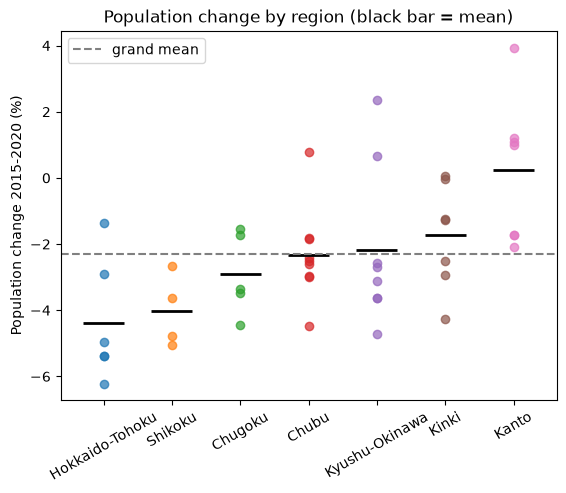

,count,mean,std
region,,,
Hokkaido-Tohoku,6,-4.37,1.84
Shikoku,4,-4.03,1.10
Chugoku,5,-2.92,1.24
Chubu,9,-2.32,1.40
Kyushu-Okinawa,8,-2.17,2.41
Kinki,7,-1.74,1.58
Kanto,7,0.24,2.20


In [24]:
# Step 2 - look at the data: every prefecture as a dot, group means as black bars; means and SDs
order = anova_data.groupby("region")["growth_5y"].mean().sort_values().index

for i, r in enumerate(order):
    values = anova_data[anova_data["region"] == r]["growth_5y"]
    plt.scatter([i] * len(values), values, alpha=0.7)
    plt.hlines(values.mean(), i - 0.3, i + 0.3, color="black", linewidth=2)

plt.axhline(anova_data["growth_5y"].mean(), color="gray", linestyle="--", label="grand mean")
plt.xticks(range(len(order)), order, rotation=30)
plt.ylabel("Population change 2015-2020 (%)")
plt.title("Population change by region (black bar = mean)")
plt.legend()
plt.show()

anova_data.groupby("region")["growth_5y"].agg(["count", "mean", "std"]).round(2).loc[order]

SD ratio (largest / smallest): 2.19 (rule of thumb: below 2)


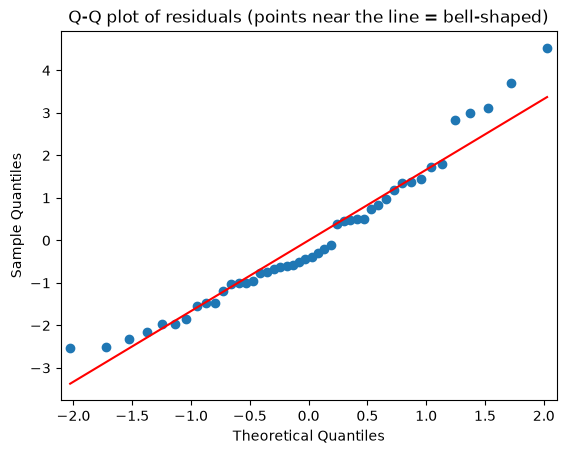

In [25]:
# Step 3 - check the conditions: equal spread (largest SD / smallest SD < 2) and bell-shaped noise (Q-Q plot)
import statsmodels.api as sm

sds = anova_data.groupby("region")["growth_5y"].std()
print("SD ratio (largest / smallest):", round(sds.max() / sds.min(), 2), "(rule of thumb: below 2)")

residuals = anova_data["growth_5y"] - anova_data.groupby("region")["growth_5y"].transform("mean")
sm.qqplot(residuals, line="s")
plt.title("Q-Q plot of residuals (points near the line = bell-shaped)")
plt.show()

In [26]:
# Step 4 - the F test: ANOVA table (between regions vs. within regions)
import statsmodels.formula.api as smf
from statsmodels.stats.anova import anova_lm
from scipy import stats

model = smf.ols("growth_5y ~ C(region)", data=anova_data).fit()
anova_table = anova_lm(model)
print(anova_table.round(4))

# Back-up test that uses ranks instead of values (if the checks in step 3 look doubtful)
groups = [g["growth_5y"].values for _, g in anova_data.groupby("region")]
kruskal_p = stats.kruskal(*groups).pvalue
print("\nKruskal-Wallis (rank test): p =", round(kruskal_p, 6))

             df    sum_sq  mean_sq       F  PR(>F)
C(region)   6.0   87.4071  14.5678  4.4695  0.0016
Residual   39.0  127.1173   3.2594     NaN     NaN

Kruskal-Wallis (rank test): p = 0.004864


In [27]:
# Step 5 - effect size: eta squared = share of all variation that lies between the regions
ss_between = anova_table.loc["C(region)", "sum_sq"]
ss_total = anova_table["sum_sq"].sum()
eta_sq = ss_between / ss_total
print("eta squared =", round(eta_sq, 2), "->", round(eta_sq * 100), "% of the variation goes with the region")

eta squared = 0.41 -> 41 % of the variation goes with the region


         Multiple Comparison of Means - Tukey HSD, FWER=0.05          
     group1          group2     meandiff p-adj   lower   upper  reject
----------------------------------------------------------------------
          Chubu         Chugoku  -0.5982 0.9966 -3.7271  2.5308  False
          Chubu Hokkaido-Tohoku  -2.0563 0.3393 -5.0128  0.9003  False
          Chubu           Kanto   2.5617 0.0978 -0.2653  5.3887  False
          Chubu           Kinki   0.5813  0.995 -2.2457  3.4083  False
          Chubu  Kyushu-Okinawa   0.1508    1.0  -2.575  2.8766  False
          Chubu         Shikoku  -1.7167 0.6939 -5.0877  1.6543  False
        Chugoku Hokkaido-Tohoku  -1.4581 0.8319  -4.855  1.9387  False
        Chugoku           Kanto   3.1598 0.0661 -0.1249  6.4445  False
        Chugoku           Kinki   1.1795 0.9194 -2.1052  4.4642  False
        Chugoku  Kyushu-Okinawa   0.7489   0.99 -2.4491   3.947  False
        Chugoku         Shikoku  -1.1185 0.9664 -4.8816  2.6446  False
Hokkai

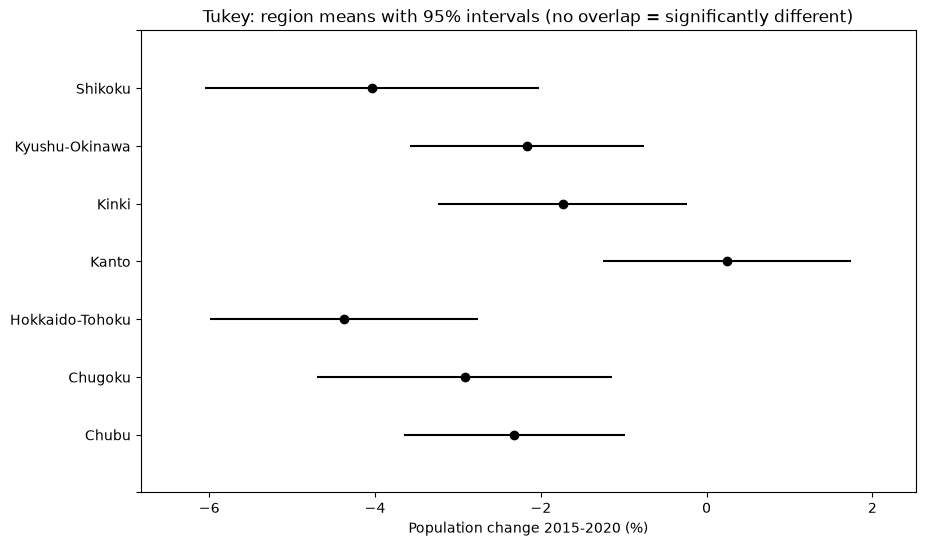

In [28]:
# Step 6 - which regions differ? Tukey's HSD (keeps the overall false-alarm rate at 5%)
from statsmodels.stats.multicomp import pairwise_tukeyhsd

tukey = pairwise_tukeyhsd(anova_data["growth_5y"], anova_data["region"])
print(tukey)

tukey.plot_simultaneous(xlabel="Population change 2015-2020 (%)")
plt.title("Tukey: region means with 95% intervals (no overlap = significantly different)")
plt.show()

In [29]:
# Step 7 - report the result in one paragraph
df_b = int(anova_table.loc["C(region)", "df"])
df_w = int(anova_table.loc["Residual", "df"])
F = anova_table.loc["C(region)", "F"]
p = anova_table.loc["C(region)", "PR(>F)"]
n_sig = int(tukey.reject.sum())

print(f"One-way ANOVA, population change 2015-2020 by region, {len(anova_data)} prefectures: "
      f"F({df_b}, {df_w}) = {F:.2f}, p = {p:.4f}; eta squared = {eta_sq:.2f}. "
      f"Tukey's HSD: {n_sig} of {len(tukey.reject)} region pairs differ significantly. "
      f"Checks: SD ratio {sds.max() / sds.min():.1f} (rule of thumb: below 2), so the rank test was also run: "
      f"Kruskal-Wallis p = {kruskal_p:.4f}, the same conclusion. Q-Q plot: see above.")

One-way ANOVA, population change 2015-2020 by region, 46 prefectures: F(6, 39) = 4.47, p = 0.0016; eta squared = 0.41. Tukey's HSD: 2 of 21 region pairs differ significantly. Checks: SD ratio 2.2 (rule of thumb: below 2), so the rank test was also run: Kruskal-Wallis p = 0.0049, the same conclusion. Q-Q plot: see above.


**Example 3 from class (same units measured repeatedly):** the same 46 prefectures are measured in every
5-year period. Did population change differ between periods? Each prefecture's own level is removed first.

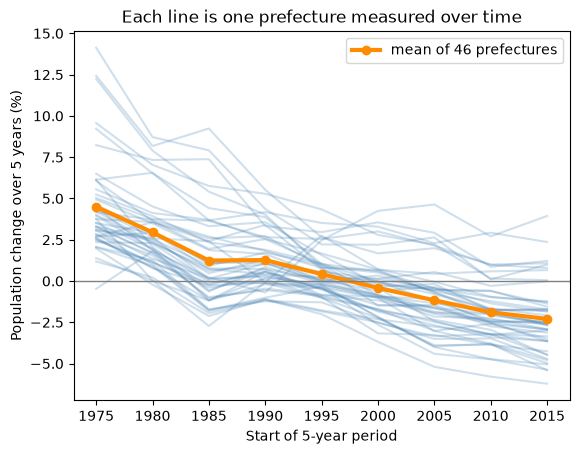

In [30]:
# Repeated measures: every prefecture is one line over the periods; the thick line is the mean
rm_data = pref5[(pref5["area"] != "Fukushima-ken")].dropna(subset=["growth_5y"])[["area", "year", "growth_5y"]]

for area, g in rm_data.groupby("area"):
    plt.plot(g["year"], g["growth_5y"], color="steelblue", alpha=0.25)
mean_line = rm_data.groupby("year")["growth_5y"].mean()
plt.plot(mean_line.index, mean_line.values, color="darkorange", linewidth=3, marker="o", label="mean of 46 prefectures")
plt.axhline(0, color="gray", linewidth=1)
plt.xlabel("Start of 5-year period")
plt.ylabel("Population change over 5 years (%)")
plt.title("Each line is one prefecture measured over time")
plt.legend()
plt.show()

In [31]:
# Repeated-measures ANOVA: does the period matter, after removing each prefecture's own level?
# (statsmodels does not give the corrected p-value from class; with an F this large the conclusion would not change)
from statsmodels.stats.anova import AnovaRM

rm = AnovaRM(rm_data, depvar="growth_5y", subject="area", within=["year"]).fit()
print(rm)

               Anova
     F Value  Num DF  Den DF  Pr > F
------------------------------------
year 165.0620 8.0000 360.0000 0.0000



In [32]:
# Which periods differ? Paired t tests between neighbouring periods, with Bonferroni's rule (p x number of tests)
wide = rm_data.pivot(index="area", columns="year", values="growth_5y")
years = list(wide.columns)
rows = []

for a, b in zip(years[:-1], years[1:]):
    t, p = stats.ttest_rel(wide[b], wide[a])
    rows.append({"pair": f"{b} vs {a}", "mean change (pp)": (wide[b] - wide[a]).mean(),
                 "t": t, "p x tests (Bonferroni)": min(p * (len(years) - 1), 1)})

pd.DataFrame(rows).round(4)

,pair,mean change (pp),t,p x tests (Bonferroni)
0,1980 vs 1975,-1.5450,-7.6428,0.0000
1,1985 vs 1980,-1.7066,-13.0870,0.0000
2,1990 vs 1985,0.0294,0.1484,1.0000
3,1995 vs 1990,-0.8520,-5.0290,0.0001
4,2000 vs 1995,-0.8360,-6.8296,0.0000
5,2005 vs 2000,-0.7484,-7.7620,0.0000
6,2010 vs 2005,-0.7268,-7.3308,0.0000
7,2015 vs 2010,-0.4020,-4.8601,0.0001


## 4. Prediction: population 5 and 10 years ahead

Inputs: the statistics chosen in Part 2, plus the population change in the previous 5 years (the recent trend).
Each model is tested on years it has not seen: **5 years** = forecast made in 2015 for 2020,
**10 years** = forecast made in 2010 for 2020.

In [33]:
# Inputs and the rows we can use (Fukushima after 2011 left out)
inputs = selected + ["growth_prev"]
model_data = pref5[pref5["fukushima_after_2011"] == False].dropna(subset=inputs)
print("Inputs:", inputs)

Inputs: ['aging_rate', 'fiscal_strength', 'marriage_rate', 'doctors', 'hospitals', 'growth_prev']


In [34]:
# A function that trains and tests three models: naive, linear regression, random forest
def compare_models(target, test_year, years_ahead):
    rows = model_data.dropna(subset=[target])
    train = rows[rows["year"] + years_ahead <= test_year]      # only outcomes known at the time of the forecast
    test  = rows[rows["year"] == test_year]

    predictions = {
        # naive: the last 5 years' change simply repeats
        "Naive (trend repeats)": (1 + test["growth_prev"] / 100) ** (years_ahead / 5) * 100 - 100,
        "Linear regression": LinearRegression().fit(train[inputs], train[target]).predict(test[inputs]),
        "Random forest": RandomForestRegressor(n_estimators=500, random_state=0)
                             .fit(train[inputs], train[target]).predict(test[inputs]),
    }
    scores = pd.DataFrame({name: {"MAE (pp)": mean_absolute_error(test[target], p),
                                  "R2": r2_score(test[target], p)} for name, p in predictions.items()}).T
    return scores.round(3), test, predictions

                       MAE (pp)     R2
Naive (trend repeats)     0.547  0.899
Linear regression         0.600  0.873
Random forest             0.812  0.748


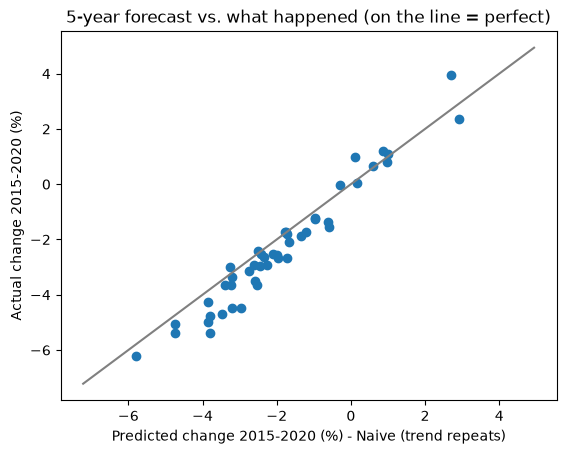

In [35]:
# 5 years ahead: learn from periods up to 2010 -> 2015, test the forecast 2015 -> 2020
scores5, test5, pred5 = compare_models("growth_5y", test_year=2015, years_ahead=5)
print(scores5)

best5 = scores5["MAE (pp)"].idxmin()
plt.scatter(pred5[best5], test5["growth_5y"])
lims = [test5["growth_5y"].min() - 1, test5["growth_5y"].max() + 1]
plt.plot(lims, lims, color="gray")
plt.xlabel(f"Predicted change 2015-2020 (%) - {best5}")
plt.ylabel("Actual change 2015-2020 (%)")
plt.title("5-year forecast vs. what happened (on the line = perfect)")
plt.show()

                       MAE (pp)     R2
Naive (trend repeats)     1.925  0.694
Linear regression         0.794  0.924
Random forest             1.370  0.789


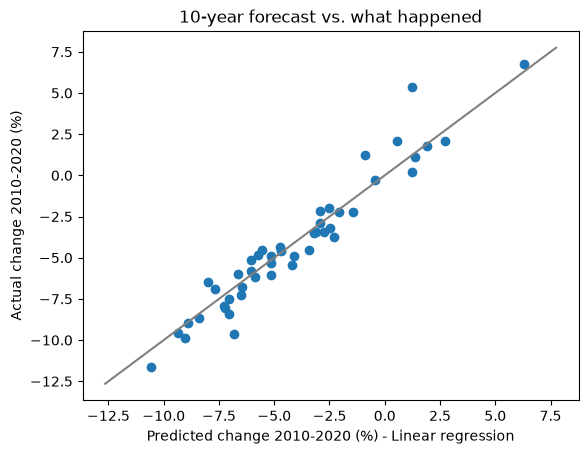

In [36]:
# 10 years ahead: learn from periods up to 2000 -> 2010, test the forecast 2010 -> 2020
scores10, test10, pred10 = compare_models("growth_10y", test_year=2010, years_ahead=10)
print(scores10)

best10 = scores10["MAE (pp)"].idxmin()
plt.scatter(pred10[best10], test10["growth_10y"])
lims = [test10["growth_10y"].min() - 1, test10["growth_10y"].max() + 1]
plt.plot(lims, lims, color="gray")
plt.xlabel(f"Predicted change 2010-2020 (%) - {best10}")
plt.ylabel("Actual change 2010-2020 (%)")
plt.title("10-year forecast vs. what happened")
plt.show()

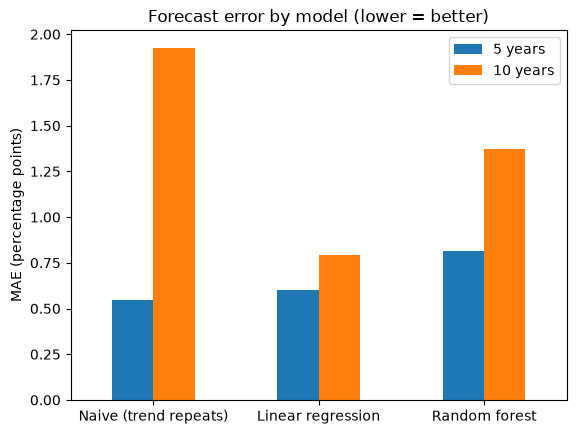

Best 5-year model: Naive (trend repeats) | Best 10-year model: Linear regression


In [37]:
# Compare the errors of all models side by side
pd.DataFrame({"5 years": scores5["MAE (pp)"], "10 years": scores10["MAE (pp)"]}).plot(
    kind="bar", title="Forecast error by model (lower = better)", ylabel="MAE (percentage points)", rot=0)
plt.show()
print("Best 5-year model:", best5, "| Best 10-year model:", best10)

In [38]:
# Forecast the future from 2020: retrain the best models on all known periods
def fit_best(name, target):
    rows = model_data.dropna(subset=[target])
    if name == "Linear regression":
        return LinearRegression().fit(rows[inputs], rows[target])
    if name == "Random forest":
        return RandomForestRegressor(n_estimators=500, random_state=0).fit(rows[inputs], rows[target])
    return None   # naive needs no training

now = model_data[model_data["year"] == 2020].copy()
for name, target, years_ahead, col in [(best5, "growth_5y", 5, "growth_2025"), (best10, "growth_10y", 10, "growth_2030")]:
    model = fit_best(name, target)
    if model is None:
        now[col] = (1 + now["growth_prev"] / 100) ** (years_ahead / 5) * 100 - 100
    else:
        now[col] = model.predict(now[inputs])

now["pop_2025"] = now["pop"] * (1 + now["growth_2025"] / 100)
now["pop_2030"] = now["pop"] * (1 + now["growth_2030"] / 100)

forecast = now[["area", "region", "pop", "growth_2025", "pop_2025", "growth_2030", "pop_2030"]].sort_values("growth_2030")
forecast.round(1)

,area,region,pop,growth_2025,pop_2025,growth_2030,pop_2030
300,Akita-ken,Tohoku,959502.0,-6.2,899840.7,-13.7,828017.1
198,Iwate-ken,Tohoku,1210534.0,-5.4,1145201.2,-12.3,1061580.9
147,Aomori-ken,Tohoku,1237984.0,-5.4,1171478.5,-12.2,1087271.2
2034,Kochi-ken,Shikoku,691527.0,-5.0,656632.4,-11.6,611484.7
351,Yamagata-ken,Tohoku,1068027.0,-5.0,1014939.8,-11.3,947538.9
810,Niigata-ken,Chubu,2201272.0,-4.5,2102883.4,-10.6,1968457.4
1830,Yamaguchi-ken,Chugoku,1342059.0,-4.5,1282184.9,-10.5,1200481.0
1881,Tokushima-ken,Shikoku,719559.0,-4.8,685116.5,-9.9,648403.0
2187,Nagasaki-ken,Kyushu-Okinawa,1312317.0,-4.7,1250502.6,-9.6,1186065.9
1575,Wakayama-ken,Kinki,922584.0,-4.3,883333.1,-9.3,836700.5


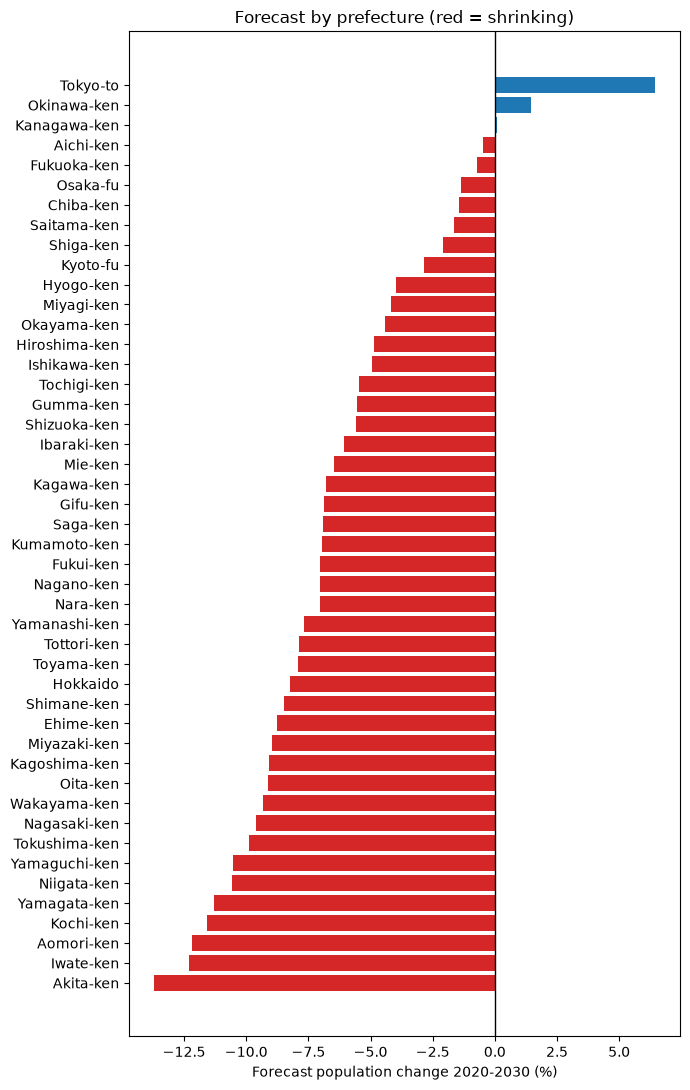

In [39]:
# Chart: forecast change 2020 -> 2030 for every prefecture
f = forecast.sort_values("growth_2030")
plt.figure(figsize=(7, 11))
plt.barh(f["area"], f["growth_2030"], color=["tab:red" if g < 0 else "tab:blue" for g in f["growth_2030"]])
plt.axvline(0, color="black", linewidth=1)
plt.xlabel("Forecast population change 2020-2030 (%)")
plt.title("Forecast by prefecture (red = shrinking)")
plt.tight_layout()
plt.show()

In [40]:
# Totals for the 46 prefectures, and a check against the real 2024 population
print(f"2020: {forecast['pop'].sum() / 1e6:.2f} million")
print(f"2025 forecast: {forecast['pop_2025'].sum() / 1e6:.2f} million")
print(f"2030 forecast: {forecast['pop_2030'].sum() / 1e6:.2f} million")

actual_2024 = pref[pref["year"] == 2024].set_index("area")["pop"]
check = forecast.set_index("area")[["pop", "growth_2025"]].copy()
check["actual_change_2020_2024"] = (actual_2024 / check["pop"] - 1) * 100
check["forecast_change_2020_2024"] = ((1 + check["growth_2025"] / 100) ** 0.8 - 1) * 100   # 4 of the 5 years

print("\nCheck against the real 2024 population:")
print("  average error:", round((check["forecast_change_2020_2024"] - check["actual_change_2020_2024"]).abs().mean(), 2), "percentage points")
print("  correlation:  ", round(check["forecast_change_2020_2024"].corr(check["actual_change_2020_2024"]), 2))

2020: 124.31 million
2025 forecast: 123.53 million
2030 forecast: 120.36 million

Check against the real 2024 population:
  average error: 1.18 percentage points
  correlation:   0.97
